In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [2]:
df = pd.read_csv('trip_data.csv', low_memory=False)

In [3]:
df.isnull().sum()

HOUSEID            0
PERSONID           0
TRPTRANS          16
TRVLCMIN        1297
TRPMILES         656
DWELTIME      219200
WHYTO            232
TRAVDAY            0
URBRUR             0
R_AGE           1216
PRMACT         79373
WORKER         79323
EDUC           65579
PAYPROF       508915
CAN-DRIVER     71889
SEX              711
HHFAMINC       24340
HHVEHCNT           0
HHSIZE             0
URBAN              0
HOMEOWN          162
dtype: int64

In [4]:
df.shape

(923572, 21)

In [5]:
df.isnull().sum() / len(df) * 100

HOUSEID        0.000000
PERSONID       0.000000
TRPTRANS       0.001732
TRVLCMIN       0.140433
TRPMILES       0.071029
DWELTIME      23.733937
WHYTO          0.025120
TRAVDAY        0.000000
URBRUR         0.000000
R_AGE          0.131663
PRMACT         8.594132
WORKER         8.588719
EDUC           7.100583
PAYPROF       55.102905
CAN-DRIVER     7.783800
SEX            0.076984
HHFAMINC       2.635420
HHVEHCNT       0.000000
HHSIZE         0.000000
URBAN          0.000000
HOMEOWN        0.017541
dtype: float64

In [6]:
df = df.drop(['DWELTIME', 'PAYPROF', 'PRMACT', 'EDUC', 'URBAN'], axis=1)

In [7]:
df = df.dropna()

In [8]:
df['SEX'].unique()

array(['Female', 'Male'], dtype=object)

In [9]:
df.isnull().sum()

HOUSEID       0
PERSONID      0
TRPTRANS      0
TRVLCMIN      0
TRPMILES      0
WHYTO         0
TRAVDAY       0
URBRUR        0
R_AGE         0
WORKER        0
CAN-DRIVER    0
SEX           0
HHFAMINC      0
HHVEHCNT      0
HHSIZE        0
HOMEOWN       0
dtype: int64

In [10]:
df.columns

Index(['HOUSEID', 'PERSONID', 'TRPTRANS', 'TRVLCMIN', 'TRPMILES', 'WHYTO',
       'TRAVDAY', 'URBRUR', 'R_AGE', 'WORKER', 'CAN-DRIVER', 'SEX', 'HHFAMINC',
       'HHVEHCNT', 'HHSIZE', 'HOMEOWN'],
      dtype='object')

In [11]:
df = df.rename(columns={'CAN-DRIVER':'DRIVER', 'HHFAMINC':'HHFAMINC (AVERAGE)'})

In [12]:
sorted_keys = sorted(df['TRPTRANS'].value_counts().keys())

In [13]:
df['TRPTRANS'].unique()

array([ 3.,  6.,  4.,  1.,  5., 97., 11.,  2., 17., 16., 15., 19.,  8.,
        9., 18., 12., 10., 13., 20.,  7., 14.])

In [14]:
print(sorted_keys)

[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 97.0]


In [15]:
df['WHYTO'].value_counts()

WHYTO
1.0     272672
11.0    122187
3.0      96507
13.0     65681
6.0      50771
17.0     32984
16.0     28157
14.0     25980
15.0     25375
12.0     22068
19.0     16111
18.0     15534
4.0      11283
7.0       7802
5.0       7792
8.0       7459
2.0       6309
97.0      1999
9.0        785
10.0       525
Name: count, dtype: int64

In [16]:
df['SEX'].unique()

array(['Female', 'Male'], dtype=object)

In [17]:
df['WHYTO'] = df['WHYTO'].map({1:'home-activity', 2: 'remote-work(home)' , 3: 'remote-work(not home)',
                               4: 'work-activity-to transport' , 5: 'work-activity-other' ,
                               6: 'school' , 7: 'childcare/adultcare' , 8: 'volunteer' , 9: 'change-transpo' ,
                               10: 'personal-dropoff/pickup' , 11: 'healthcare-visit' , 12: 'buy-meals' ,
                               13: 'shop-activity' , 14: 'personal/family-errands' , 15: 'recreation' ,
                               16: 'exercise' , 17: 'visit-friends/family' , 18: 'vacation' , 
                               19:'religous-activity', 97:'none-of-above'})

df['URBRUR'] = df['URBRUR'].map({1:'Urban', 2:'Rural'})
df['WORKER'] = df['WORKER'].map({1:'Worker', 2:'Not Worker'})
df['DRIVER'] = df['DRIVER'].map({1:'Yes', 2:'No'})
df['HHFAMINC (AVERAGE)'] = df['HHFAMINC (AVERAGE)'].map({1:10000, 2: 12500, 3: 20000, 4: 30000, 5:42500, 6:62500, 7: 87500, 8: 122500, 9:137500, 10:175000, 11: 200000})
df['TRPTRANS'] = df['TRPTRANS'].map({1:'car', 2: 'van' , 3: 'suv',
                               4: 'pickup-truck'  , 5: 'pickup-truck',
                               6: 'pickup-truck' , 7: 'motorcycle' , 8: 'public-bus' , 9: 'school-bus' ,
                                10: 'street-car' , 11: 'subway' , 12: 'comm-rail' ,
                               13: 'amtrak' , 14: 'airplane' , 15: 'taxi' ,
                               16: 'ride-share' , 17: 'paratransit' , 18: 'bicycle' , 
                               19:'e-scooter', 20:'walked', 97: 'noneabove' })

In [18]:
df['TRPTRANS'].value_counts()

TRPTRANS
suv             363086
pickup-truck    349712
car              71569
van               6310
subway            6117
ride-share        3153
noneabove         3061
paratransit       2664
public-bus        2023
bicycle           1859
street-car        1830
e-scooter         1648
amtrak            1329
taxi              1096
motorcycle         744
school-bus         724
comm-rail          568
walked             375
airplane           113
Name: count, dtype: int64

In [19]:
percentages = df['TRPTRANS'].value_counts(normalize=True) * 100
threshold = 1
rare_classes = percentages[percentages  < threshold].index.tolist()
print(rare_classes)

df['Transport_mode'] = df['TRPTRANS'].apply(lambda x : x if x not in rare_classes else 'other_mode')

df = df.drop('TRPTRANS', axis=1)

['van', 'subway', 'ride-share', 'noneabove', 'paratransit', 'public-bus', 'bicycle', 'street-car', 'e-scooter', 'amtrak', 'taxi', 'motorcycle', 'school-bus', 'comm-rail', 'walked', 'airplane']


In [20]:
df['Transport_mode'].value_counts()

Transport_mode
suv             363086
pickup-truck    349712
car              71569
other_mode       33614
Name: count, dtype: int64

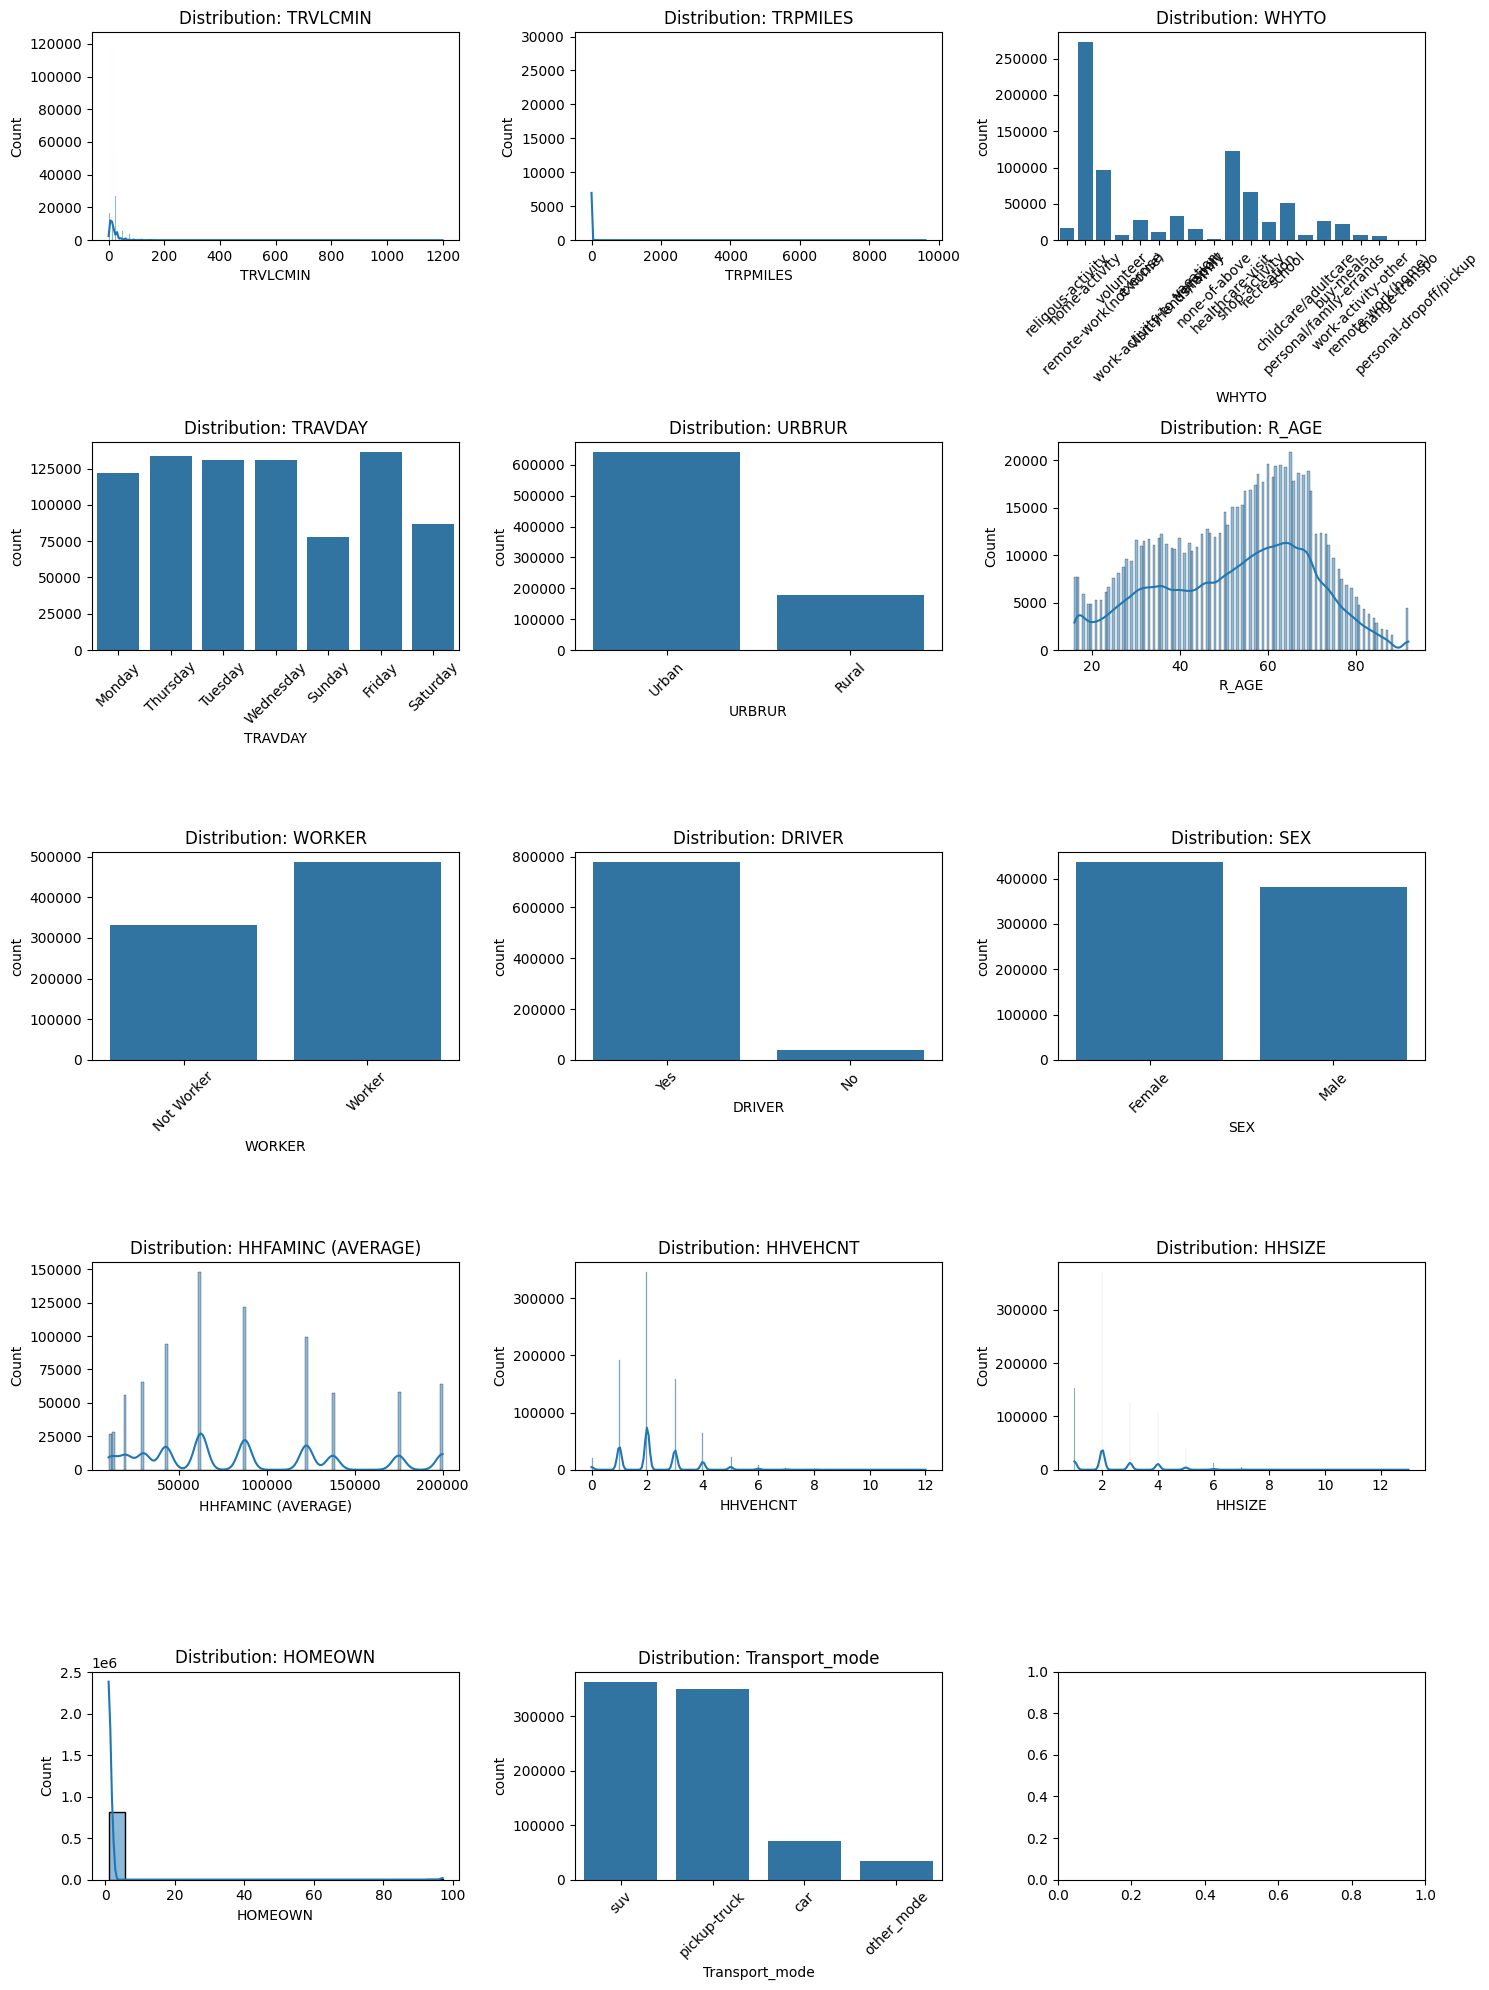

In [21]:
skip_cols = ['HOUSEID', 'PERSONID']
cols_to_plot = [col for col in df.columns if col not in skip_cols]

n_cols = 3
n_rows = math.ceil(len(cols_to_plot) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 4*n_rows))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    ax = axes[i]
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        sns.countplot(data=df, x=col, ax=ax)
        ax.tick_params(axis='x', rotation=45)

    else:
        sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution: {col}')

plt.tight_layout()

In [22]:
df['TRAVDAY'].unique()

array(['Monday', 'Thursday', 'Tuesday', 'Wednesday', 'Sunday', 'Friday',
       'Saturday'], dtype=object)

In [23]:
day_order = day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

week_trip_sum = df.groupby('TRAVDAY')['TRPMILES'].sum().reindex(day_order).reset_index()

In [24]:
week_trip_sum.head()

,TRAVDAY,TRPMILES
0,Monday,1322551.654
1,Tuesday,1291127.569
2,Wednesday,1470375.553
3,Thursday,1435159.562
4,Friday,1613447.636


In [25]:
weekmiles_averages = df.groupby('TRAVDAY')['TRPMILES'].mean()

weekmiles_averages = weekmiles_averages.reindex(day_order)

In [26]:
weekmiles_averages

TRAVDAY
Monday       10.838100
Tuesday       9.876140
Wednesday    11.255688
Thursday     10.746234
Friday       11.836171
Saturday     11.769862
Sunday       12.970243
Name: TRPMILES, dtype: float64

In [27]:
df['Transport_mode'].isnull().sum()

np.int64(0)

In [28]:
df.isnull().sum()

HOUSEID               0
PERSONID              0
TRVLCMIN              0
TRPMILES              0
WHYTO                 0
TRAVDAY               0
URBRUR                0
R_AGE                 0
WORKER                0
DRIVER                0
SEX                   0
HHFAMINC (AVERAGE)    0
HHVEHCNT              0
HHSIZE                0
HOMEOWN               0
Transport_mode        0
dtype: int64

In [29]:
df['Transport_mode'].value_counts()

Transport_mode
suv             363086
pickup-truck    349712
car              71569
other_mode       33614
Name: count, dtype: int64

In [30]:
df.shape

(817981, 16)

In [31]:
df.to_csv('final_data.csv', index=False)